In [3]:
# install pandas
%pip install pandas


Note: you may need to restart the kernel to use updated packages.


In [1]:
# ============================================================
# AI-Assisted Network Anomaly Detection
# Step 1: Load the network traffic dataset
# ============================================================

# Import pandas to load and analyze the CSV dataset.
import pandas as pd
# Load the feature dataset exported from the Ubuntu sensor VM.
df = pd.read_csv("windows_vm_dataset_updated.csv")

# Display the first 5 rows to verify that the dataset loaded correctly.
display(df.head())


,minute,device_ip,packet_count,total_bytes,average_packet_size,tcp_count,udp_count,unique_destinations,unique_ports,dns_count
0,2026-09-17 01:40,192.168.50.10,176,45842,260.465909,163,13,10,2,13
1,2026-10-04 00:49,192.168.50.10,599,140018,233.752922,582,17,31,3,5
2,2026-10-04 00:50,192.168.50.10,936,894425,955.582265,924,12,57,3,6
3,2026-10-04 00:51,192.168.50.10,816,296069,362.829657,793,23,75,4,21
4,2026-10-04 00:52,192.168.50.10,647,291583,450.669243,616,27,77,3,11


In [2]:

# ============================================================
# Step 2: Inspect the network traffic dataset
# ============================================================

# Display the number of rows and columns in the dataset.
# Each row represents one minute of traffic from the Windows VM.
print("Dataset shape:", df.shape)

# Display the names of the dataset columns.
print("\nColumn names:")
print(df.columns.tolist())

# Check each column's data type and identify missing values.
print("\nDataset information:")
df.info()

# Display summary statistics for the numerical columns.
# This helps us understand the range and variation of network traffic.
print("\nSummary statistics:")
display(df.describe())


Dataset shape: (177, 10)

Column names:
['minute', 'device_ip', 'packet_count', 'total_bytes', 'average_packet_size', 'tcp_count', 'udp_count', 'unique_destinations', 'unique_ports', 'dns_count']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 177 entries, 0 to 176
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   minute               177 non-null    str    
 1   device_ip            177 non-null    str    
 2   packet_count         177 non-null    int64  
 3   total_bytes          177 non-null    int64  
 4   average_packet_size  177 non-null    float64
 5   tcp_count            177 non-null    int64  
 6   udp_count            177 non-null    int64  
 7   unique_destinations  177 non-null    int64  
 8   unique_ports         177 non-null    int64  
 9   dns_count            177 non-null    int64  
dtypes: float64(1), int64(7), str(2)
memory usage: 14.0 KB

Summary statistics:


,packet_count,total_bytes,average_packet_size,tcp_count,udp_count,unique_destinations,unique_ports,dns_count
count,177.000000,1.770000e+02,177.000000,177.000000,177.000000,177.000000,177.000000,177.000000
mean,629.581921,2.234811e+05,348.780333,604.870056,24.333333,44.050847,2.389831,3.598870
std,469.329037,2.843570e+05,259.386461,447.339509,47.253387,55.173515,1.257030,7.584569
min,2.000000,1.200000e+02,60.000000,2.000000,0.000000,1.000000,1.000000,0.000000
25%,238.000000,5.204000e+04,72.569378,233.000000,0.000000,8.000000,1.000000,0.000000
50%,442.000000,1.147490e+05,347.411523,436.000000,5.000000,24.000000,2.000000,0.000000
75%,1038.000000,2.809620e+05,528.162216,972.000000,27.000000,60.000000,3.000000,4.000000
max,1973.000000,1.394261e+06,1073.552752,1881.000000,392.000000,298.000000,8.000000,54.000000


In [3]:
# ===========================================================
# Step 3: Prepare the numerical features for machine learning
# ===========================================================

# Import NumPy for numerical operations.
import numpy as np

# Select the eight numerical traffic features.
# We exclude the timestamp and device IP because they identify.
# each record rather than measure traffic behavior

feature_columns = [
    "packet_count",
    "total_bytes",
    "average_packet_size",
    "tcp_count",
    "udp_count",
    "unique_destinations",
    "unique_ports",
    "dns_count"
]

# Create a seperate DataFrame containing only the model featueres
X = df[feature_columns].copy()

# Convert all selected features to numeric values.
# Invalid values will become missiing values(NaN).
X = X.apply(pd.to_numeric, errors="coerce")

# Check for missing or infinite values before training.
X = X.replace([np.inf, -np.inf], np.nan)

# Remove records containing missing feature values.
X = X.dropna()

print("Feature matrix shape after cleaning:", X.shape)
print("Remaining missing values:", X.isnull().sum().sum())

print("Feature matrix shape:", X.shape)
print("Missing values per feature:")
print(X.isnull().sum())

# Stop if any missing or infinite values need to be handled.
if X.isnull().any().any():
    raise ValueError("Missing or invalid values found. Clean the data before training")

# Display the first five rows of prepared feature matrix.
display(X.head())
 

Feature matrix shape after cleaning: (177, 8)
Remaining missing values: 0
Feature matrix shape: (177, 8)
Missing values per feature:
packet_count           0
total_bytes            0
average_packet_size    0
tcp_count              0
udp_count              0
unique_destinations    0
unique_ports           0
dns_count              0
dtype: int64


,packet_count,total_bytes,average_packet_size,tcp_count,udp_count,unique_destinations,unique_ports,dns_count
0,176,45842,260.465909,163,13,10,2,13
1,599,140018,233.752922,582,17,31,3,5
2,936,894425,955.582265,924,12,57,3,6
3,816,296069,362.829657,793,23,75,4,21
4,647,291583,450.669243,616,27,77,3,11


In [4]:
# =================================================
# Step 4: Split the dataset chronologically
# =================================================


# Calculate the index separating the first 80% from the final 20%
# The dataset is already ordered by minute when it was exported

split_index = int(len(X) * 0.80) 

# Use the earlier 80% of records to train the model.
X_train = X.iloc[:split_index].copy()

# Reserve the later 20% to test the model on unseen records.
X_test = X.iloc[split_index:].copy()

# Keep the timestamps so we can identify when anomalies occur.
test_timestamps = df["minute"].iloc[split_index:].reset_index(drop=True)



In [5]:
# ============================================================
# Step 5A: Install the machine learning library
# ============================================================

# Install scikit-learn, which provides the Isolation Forest model.
# The %pip command installs it into the notebook's active environment.
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [6]:
# Step 5B: Train the Isolation Forest anomaly detection model
# ===========================================================

# Import Isolation Forest, an unsupervised machine learning algorithm
from sklearn.ensemble import IsolationForest

# Create the model.
# n_estimators=100 means the model uses 100 decision trees.
# contamination="auto" lets the algorithm use its default threshold.
# for deciding which records appear unusual.
# random_state=42 makes results reproducible between runs.

model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

# Train the model using only the first 80% of the traffic.
# The model learns patterns from, these earlier records.

model.fit(X_train)

# Confirm the training completed.
print("Isolation Forest model trained successfully.")
print("Training records used:", len(X_train))



Isolation Forest model trained successfully.
Training records used: 141


In [7]:
# ===============================================
# Step 6: Detect anomalies in the testing dataset
# ===============================================

# Ask the trained model to classify the testing records.
# The model returns:
# 1 = normal traffic
#-1 = potentially anomalous traffic

predictions = model.predict(X_test)

# Calculate an anomaly score for each testing record.
# Lower scores indicate records that appear more unusual.

anomaly_scores = model.decision_function(X_test)

# Display how many records were tested.
print("Testing records used:", len(X_test))

# Count the record classified as normal.
print("Normal records:", (predictions == 1).sum())

# Count the records classified as anomalies.
print("Potential anomalies:", (predictions == -1).sum())




Testing records used: 36
Normal records: 34
Potential anomalies: 2


In [8]:
# ============================================================
# Step 7: Display the records flagged as potential anomalies
# ============================================================

# Copy the testing records so we don't modify the original data.
results = X_test.copy()

# Attach the timestamps of the testing records.
results["minute"] = test_timestamps.values

# Attach the Windows VM's IP address.
results["device_ip"] = df["device_ip"].iloc[split_index:].values

# Store the model's predictions.
results["prediction"] = predictions

# Store the anomaly scores.
results["anomaly_scores"] = anomaly_scores

# Select only records that the model flagged as anomalies.
anomalies = results[results["prediction"] == -1]

# Display the flagged records for investigation.
display(anomalies)

,packet_count,total_bytes,average_packet_size,tcp_count,udp_count,unique_destinations,unique_ports,dns_count,minute,device_ip,prediction,anomaly_scores
150,187,164930,881.978610,179,8,12,1,0,2026-10-06 19:35,192.168.50.10,-1,-0.019686
173,808,155803,192.825495,780,28,32,3,28,2026-11-08 01:52,192.168.50.10,-1,-0.007087


In [9]:
# ============================================================
# Step 8: Examine the traffic features flagged as anomalous
# ============================================================

# Display only the numerical features used by the model.
# This lets us focus on the traffic characteristics.
display(anomalies[feature_columns])

,packet_count,total_bytes,average_packet_size,tcp_count,udp_count,unique_destinations,unique_ports,dns_count
150,187,164930,881.978610,179,8,12,1,0
173,808,155803,192.825495,780,28,32,3,28


In [10]:
# ===============================================
# Step 9: Examine the training data baseline
# ===============================================

# Calculate descriptive statistics for each traiffic
# These statistics help us understand the typical traffic pattern
# in the data used to train our model.

baseline_stats = X_train.describe(
    percentiles=[0.50, 0.95, 0.99]
).T

# Display the statistics for all eight traffic features.
display(baseline_stats)

,count,mean,std,min,50%,95%,99%,max
packet_count,141.0,725.276596,472.213513,6.0,713.000000,1523.000000,1.760200e+03,1.973000e+03
total_bytes,141.0,257686.241135,305324.244310,600.0,140018.000000,919575.000000,1.312857e+06,1.394261e+06
average_packet_size,141.0,349.634505,254.293256,60.0,362.099386,786.225207,9.618980e+02,9.846456e+02
tcp_count,141.0,695.567376,450.176589,6.0,639.000000,1406.000000,1.729000e+03,1.881000e+03
udp_count,141.0,29.432624,51.639313,0.0,10.000000,131.000000,2.072000e+02,3.920000e+02
unique_destinations,141.0,51.042553,59.600680,1.0,27.000000,193.000000,2.496000e+02,2.980000e+02
unique_ports,141.0,2.460993,1.322971,1.0,2.000000,5.000000,5.600000e+00,8.000000e+00
dns_count,141.0,3.780142,7.958905,0.0,0.000000,21.000000,2.960000e+01,5.400000e+01


In [20]:
# ============================================================
# Step 10: Compare all flagged records with training statistics
# ============================================================

# Calculate training statistics once
training_mean = X_train.mean()
training_std = X_train.std()

# Analyze every flagged record
for number, (_, anomaly) in enumerate(anomalies.iterrows(), start=1):

    print(f"\nAnomaly #{number}")
    print(f"Timestamp: {anomaly['minute']}")
    print(f"Device IP: {anomaly['device_ip']}")

    # Extract this anomaly's numerical features
    flagged_values = anomaly[feature_columns]

    # Compare against training statistics
    comparison = pd.DataFrame({
        "flagged_value": flagged_values,
        "training_mean": training_mean,
        "training_std": training_std
    })

    # Calculate deviation from the training mean
    comparison["standard_deviations_from_mean"] = (
        (comparison["flagged_value"] - comparison["training_mean"])
        / comparison["training_std"]
    )

    display(comparison.round(3))



Anomaly #1
Timestamp: 2026-10-06 19:35
Device IP: 192.168.50.10


,flagged_value,training_mean,training_std,standard_deviations_from_mean
packet_count,187,725.277,472.214,-1.139901
total_bytes,164930,257686.241,305324.244,-0.303796
average_packet_size,881.97861,349.635,254.293,2.093426
tcp_count,179,695.567,450.177,-1.147477
udp_count,8,29.433,51.639,-0.415045
unique_destinations,12,51.043,59.601,-0.655069
unique_ports,1,2.461,1.323,-1.104327
dns_count,0,3.780,7.959,-0.474958



Anomaly #2
Timestamp: 2026-11-08 01:52
Device IP: 192.168.50.10


,flagged_value,training_mean,training_std,standard_deviations_from_mean
packet_count,808,725.277,472.214,0.175182
total_bytes,155803,257686.241,305324.244,-0.333689
average_packet_size,192.825495,349.635,254.293,-0.616646
tcp_count,780,695.567,450.177,0.187554
udp_count,28,29.433,51.639,-0.027743
unique_destinations,32,51.043,59.601,-0.319502
unique_ports,3,2.461,1.323,0.407422
dns_count,28,3.780,7.959,3.043114


In [15]:
# Install Matplotlib in the notebook's active Python environment.
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


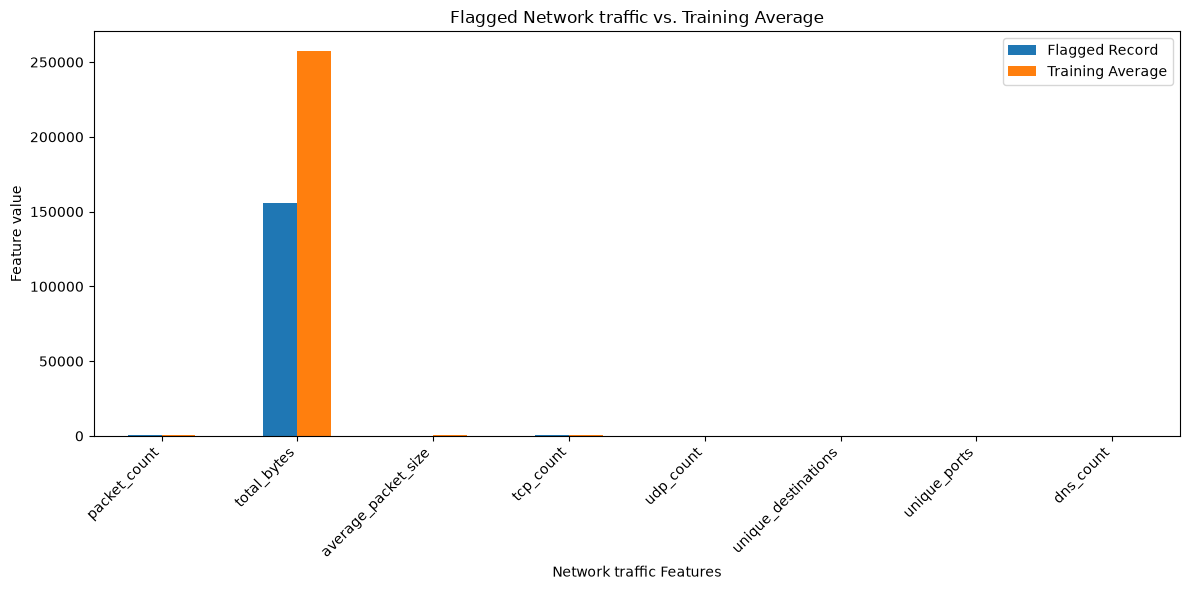

In [21]:
# ============================================================
# Step 11: Visualize the flagged record against training means
# ============================================================

import matplotlib.pyplot as plt

# Create a chart comparing the flagged record with the training average.
comparison[["flagged_value", "training_mean"]].plot(
    kind="bar",
    figsize=(12, 6)
)

# Add a descriptive title and axis labels.
plt.title("Flagged Network traffic vs. Training Average")
plt.xlabel("Network traffic Features")
plt.ylabel("Feature value")

# Rotate the feature names so they are easier to read.
plt.xticks(rotation = 45, ha="right")

# Display the legend and adjust the layout.
plt.legend(["Flagged Record", "Training Average"])
plt.tight_layout()

# Display the chart.
plt.show()



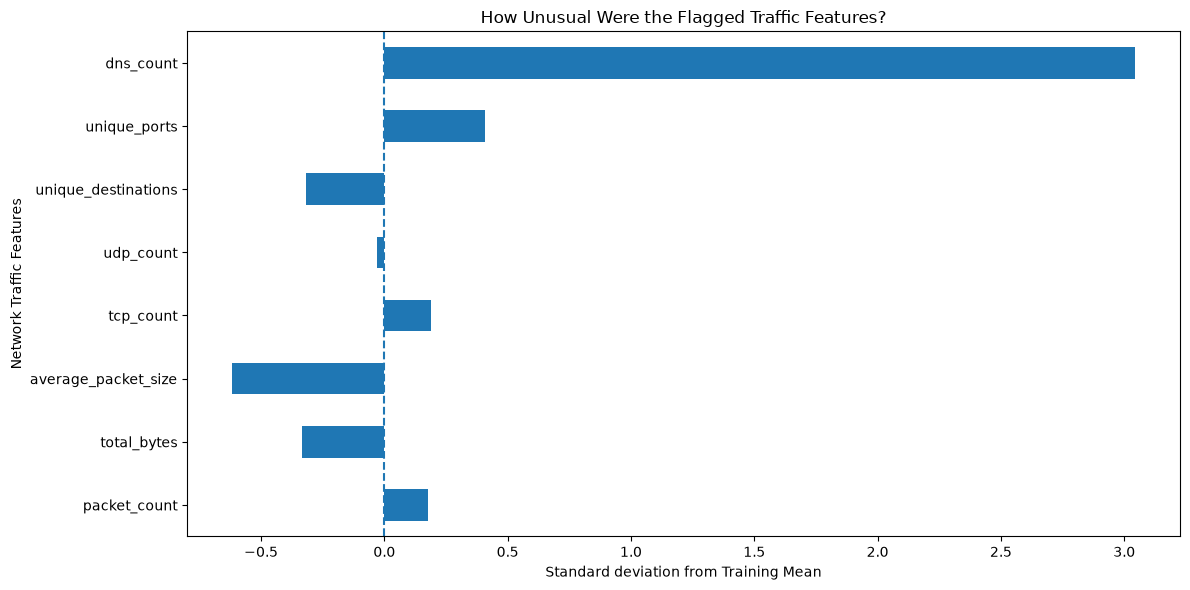

In [17]:
# =============================================================
# Step 12: Visualize standard deviations from the training mean
# =============================================================

# Create a horizontal bar chart using the standard-deviation nvalues.
comparison["standard_deviations_from_mean"].plot(
    kind="barh",
    figsize=(12, 6)
)

# Add a vertical reference line at zero (the training average).
plt.axvline(x=0, linestyle="--")

# Add a descriptive title and axis labels.
plt.title("How Unusual Were the Flagged Traffic Features?")
plt.xlabel("Standard deviation from Training Mean")
plt.ylabel("Network Traffic Features")

# Add spacing so labels and the title are not cut off.
plt.tight_layout()

# Display the chart.
plt.show()



In [23]:
# ============================================================
# Step 13: Identify the timestamps of all flagged records
# ============================================================

if anomalies.empty:
    print("No anomalies detected.")

else:
    for number, (_, anomaly) in enumerate(anomalies.iterrows(), start=1):

        print(f"\nAnomaly #{number}")
        print("Flagged traffic timestamp:", anomaly["minute"])
        print("Device IP:", anomaly["device_ip"])


Anomaly #1
Flagged traffic timestamp: 2026-10-06 19:35
Device IP: 192.168.50.10

Anomaly #2
Flagged traffic timestamp: 2026-11-08 01:52
Device IP: 192.168.50.10


In [ ]:
# ============================================================
# Step 14: Final Anomaly Detection Report
# ============================================================

# Display the report heading.
print("NETWORK ANOMALY DETECTION REPORT")
print("=" * 60)

# Display the total number of testing records and detection results.
print(f"\nTotal testing records: {len(X_test)}")

# Calculate the number of normal records using the results DataFrame.
print(f"Normal records: {(results['prediction'] == 1).sum()}")

# Display the total number of potential anomalies detected.
print(f"Potential anomalies: {len(anomalies)}")

# Check whether the model detected any anomalies.
if anomalies.empty:
    print("\nNo anomalies detected.")

else:
    # Display a summary of all flagged records.
    print("\nFlagged Records:")

    display(
        anomalies[
            ["minute", "device_ip", "anomaly_scores"]
        ].reset_index(drop=True)
    )

    # Display investigation details for each flagged record.
    print("\nInvestigation Summary:")

    for number, (_, anomaly) in enumerate(anomalies.iterrows(), start=1):

        # Display the anomaly number, timestamp, device IP, and score.
        print(f"\nAnomaly #{number}")
        print(f"Timestamp: {anomaly['minute']}")
        print(f"Device IP: {anomaly['device_ip']}")
        print(f"Anomaly Score: {anomaly['anomaly_scores']:.6f}")

# Indicate that report generation is complete.
print("\nReport generation complete.")

NETWORK ANOMALY DETECTION REPORT

Total testing records: 36
Normal records: 34
Potential anomalies: 2

Flagged Records:


,minute,device_ip,anomaly_scores
0,2026-10-06 19:35,192.168.50.10,-0.019686
1,2026-11-08 01:52,192.168.50.10,-0.007087



Investigation Summary:

Anomaly #1
Timestamp: 2026-10-06 19:35
Device IP: 192.168.50.10
Anomaly Score: -0.019686

Anomaly #2
Timestamp: 2026-11-08 01:52
Device IP: 192.168.50.10
Anomaly Score: -0.007087

Report generation complete.


In [26]:
# ============================================================
# Step 15: Save the trained anomaly detection model
# ============================================================

# Import joblib to save the trained model.
import joblib

# Package the model and its feature configuration together.
model_bundle = {
    "model": model,
    "feature_columns": feature_columns
}

# Save the model bundle to a file.
joblib.dump(model_bundle, "isolation_forest_model.joblib")

# Confirm the model was saved successfully.
print("Anomaly detection model saved successfully.")
print("Model file: isolation_forest_model.joblib")
print("Features saved:", feature_columns)

Anomaly detection model saved successfully.
Model file: isolation_forest_model.joblib
Features saved: ['packet_count', 'total_bytes', 'average_packet_size', 'tcp_count', 'udp_count', 'unique_destinations', 'unique_ports', 'dns_count']
